# Faster R-CNN smoke test

This notebook checks that the two-stage pipeline runs end to end on a few frames:
data subset, pretrained model, a short overfit run, evaluation and a submission file.
It is a correctness check, not an experiment. Its metrics come from four validation
frames after a few dozen updates and must not be compared with any model.

The same notebook runs on a local CPU and on a Kaggle GPU. Only the configuration file
differs: `config/faster_rcnn_smoke.toml` for CPU and `config/faster_rcnn_smoke_gpu.toml`
when CUDA is available.

**Configuration tables.**
`[dataset]` lists the selected frames per split and clip.
`[model]` holds the `build_faster_rcnn` arguments: resize, anchor sizes, RPN proposal
counts, RoI sampling, the detection cap and the ignored-region rule.
`[training]` holds device, threads, seed, batch size, learning rate, warmup and the number
of passes over the training frames.
`[evaluation]` holds the loader settings and the loss decrease required to pass.

## 1. Environment

On Kaggle we find the repository among the attached datasets and install the few
project packages missing from the Kaggle image. Locally we run from `notebooks/`.

In [1]:
import importlib.util
import json
import math
import platform
import resource
import subprocess
import sys
import time
import tomllib
from io import BytesIO
from pathlib import Path

NOTEBOOK_STARTED = time.perf_counter()
KAGGLE_INPUT = Path("/kaggle/input")
IS_KAGGLE = KAGGLE_INPUT.is_dir()

if IS_KAGGLE:
    candidates = [
        path
        for depth in range(1, 6)
        for path in KAGGLE_INPUT.glob("*/" * depth + "src/hm2/faster_rcnn.py")
    ]
    if not candidates:
        raise FileNotFoundError("Attach the hm2 code dataset to this notebook.")
    REPOSITORY_ROOT = candidates[0].parents[2]
else:
    REPOSITORY_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPOSITORY_ROOT / "src"))

required = {"decouple": "python-decouple", "pycocotools": "pycocotools", "polars": "polars"}
missing = [
    package for module, package in required.items() if importlib.util.find_spec(module) is None
]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)

In [2]:
import logging

import plotly.express as px
import polars as pl
import torch
import torchvision
from decouple import config
from IPython.display import Image as DisplayImage
from IPython.display import Markdown, display
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

from hm2.data import compare_yolo_coco, find_dataset_root, read_yolo_boxes
from hm2.dense_evaluation import evaluate_detections
from hm2.detection_data import make_loader
from hm2.evaluation import predictions_to_coco
from hm2.faster_rcnn import (
    IgnoreAwareDetectionDataset,
    build_faster_rcnn,
    compare_loss_windows,
    summarize_ignore_assignment,
)
from hm2.retinanet import make_optimizer, predict_loader, train_steps
from hm2.smoke_subset import flight_prefix, load_smoke_tables, prepare_smoke_subset
from hm2.submission import build_submission, validate_submission
from hm2.visualization import draw_frame

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s [%(levelname)s] %(name)s: %(message)s",
    datefmt="%Y-%m-%dT%H:%M:%S",
    stream=sys.stdout,
    force=True,
)

CONFIG_PATH = (
    REPOSITORY_ROOT
    / "config"
    / ("faster_rcnn_smoke_gpu.toml" if torch.cuda.is_available() else "faster_rcnn_smoke.toml")
)
SETTINGS = tomllib.loads(CONFIG_PATH.read_text())
TRAINING = SETTINGS["training"]
EVALUATION = SETTINGS["evaluation"]
DEVICE = torch.device(
    ("cuda" if torch.cuda.is_available() else "cpu")
    if TRAINING["device"] == "auto"
    else TRAINING["device"]
)
torch.set_num_threads(TRAINING["num_threads"])
WORK_ROOT = Path("/kaggle/working") if IS_KAGGLE else REPOSITORY_ROOT.parent
OUTPUT_DIRECTORY = (
    Path("/kaggle/working") if IS_KAGGLE else REPOSITORY_ROOT
) / "runs/faster_rcnn_smoke"
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)

pl.DataFrame(
    {
        "Python": [platform.python_version()],
        "PyTorch": [torch.__version__],
        "TorchVision": [torchvision.__version__],
        "Device": [str(DEVICE)],
        "GPU": [torch.cuda.get_device_name() if DEVICE.type == "cuda" else "None"],
        "CPU threads": [torch.get_num_threads()],
        "Config": [CONFIG_PATH.name],
    }
)

Python,PyTorch,TorchVision,Device,GPU,CPU threads,Config
str,str,str,str,str,i64,str
"""3.14.10""","""2.15.0+cu132""","""0.29.2+cu132""","""cpu""","""None""",4,"""faster_rcnn_smoke.toml"""


## 2. Tiny subset grouped by sequence

We copy only the configured frames from the competition ZIP (locally) or from the
read-only competition input (Kaggle). Training uses two clips from two different flights,
including a 2688 × 1512 frame with more than 100 targets. Validation uses one clip from a
third flight. Clips cut from the same flight share a prefix such as `uav0000013`, so we
check separation by flight, not only by clip. Test clip names are anonymised and only
provide frames for the submission check.

In [3]:
if IS_KAGGLE:
    DATA_SOURCE = find_dataset_root(KAGGLE_INPUT)
    if DATA_SOURCE is None:
        raise FileNotFoundError("Attach the competition dataset to this notebook.")
else:
    default_archive = Path.home() / "Downloads/multiple-object-video-detection-hw-2-ucu-ai-2026.zip"
    DATA_SOURCE = Path(config("HM2_DATA_SOURCE", default=str(default_archive))).expanduser()
selection = {split: SETTINGS["dataset"][f"{split}_frames"] for split in ("train", "val", "test")}
SUBSET_ROOT = prepare_smoke_subset(DATA_SOURCE, WORK_ROOT / "hm2_smoke_data", selection)
frames, objects, ignored = load_smoke_tables(SUBSET_ROOT)
train_frames, val_frames, test_frames = (
    frames.filter(pl.col("split") == split) for split in ("train", "val", "test")
)

train_flights = {flight_prefix(clip) for clip in train_frames["clip"]}
val_flights = {flight_prefix(clip) for clip in val_frames["clip"]}
if train_flights & val_flights:
    raise ValueError("Train and validation share a flight.")

(
    frames.group_by("split", maintain_order=True)
    .agg(
        pl.len().alias("Frames"),
        pl.col("clip").unique().sort().str.join(", ").alias("Clips"),
        pl.format("{}×{}", "image_width", "image_height")
        .unique()
        .sort()
        .str.join(", ")
        .alias("Sizes"),
    )
    .join(objects.group_by("split").len("Targets"), on="split", how="left")
    .join(ignored.group_by("split").len("Ignored regions"), on="split", how="left")
)

2026-11-05T23:57:13 [INFO] hm2.smoke_subset: Reuse prepared subset /home/hayevska/yustya_ubuntu/ШІ/hm2_smoke_data


split,Frames,Clips,Sizes,Targets,Ignored regions
str,u32,str,str,u32,u32
"""train""",8,"""uav0000013_00000_v, uav0000138…","""1344×756, 2688×1512""",704,52
"""val""",4,"""uav0000182_00000_v""","""1344×756""",206,7
"""test""",4,"""clip_004""","""1344×756""",null,null


## 3. Label and box conventions

YOLO files store `class cx cy w h` normalised by the image size, with classes 0 to 7.
Torchvision detectors reserve label 0 for background, so training labels are 1 to 8 and
boxes are pixel `x1 y1 x2 y2`. COCO and the submission use the top-left corner plus width
and height in original pixels. We trace one YOLO line through these conversions, compare
every validation YOLO file with the original COCO records, and draw the boxes.

In [4]:
first = train_frames.row(0, named=True)
label_path = SUBSET_ROOT / f"train/labels/{first['clip']}/{first['frame']}.txt"
yolo_line = label_path.read_text().splitlines()[0]
class_id, x, y, width, height = read_yolo_boxes(
    label_path, first["image_width"], first["image_height"]
)[0]
train_dataset = IgnoreAwareDetectionDataset(
    SUBSET_ROOT, train_frames, objects, ignored, TRAINING["flip_probability"]
)
_, first_target = train_dataset[0]
pl.DataFrame(
    {
        "YOLO line": [yolo_line],
        "Image size": [f"{first['image_width']}×{first['image_height']}"],
        "Pixel x y w h": [[round(value, 2) for value in (x, y, width, height)]],
        "Torchvision x1 y1 x2 y2": [
            [round(value, 2) for value in first_target["boxes"][0].tolist()]
        ],
        "Torchvision label": [int(first_target["labels"][0])],
        "Submission class": [int(first_target["labels"][0]) - 1],
    }
)

YOLO line,Image size,Pixel x y w h,Torchvision x1 y1 x2 y2,Torchvision label,Submission class
str,str,list[f64],list[f64],i64,i64
"""0 0.328497 0.776455 0.026042 0…","""1344×756""","[424.0, 543.0, … 88.0]","[424.0, 543.0, … 631.0]",1,0


In [5]:
val_objects = objects.filter(pl.col("split") == "val")
val_ignored = ignored.filter(pl.col("split") == "val")
conversion = compare_yolo_coco(
    SUBSET_ROOT, val_frames, val_objects, val_ignored, sample_size=val_frames.height
)
if not conversion["is_match"].all():
    raise ValueError("Validation YOLO files and COCO records disagree.")
conversion

image_key,targets,ignored_regions,max_error_px,is_match
str,i64,i64,f64,bool
"""val/uav0000182_00000_v/0000001""",27,2,0.000864,true
"""val/uav0000182_00000_v/0000101""",34,2,0.000896,true
"""val/uav0000182_00000_v/0000201""",59,2,0.000896,true
"""val/uav0000182_00000_v/0000301""",86,1,0.000832,true


**Ground truth and ignored regions (magenta).** `val/uav0000182_00000_v/0000301`

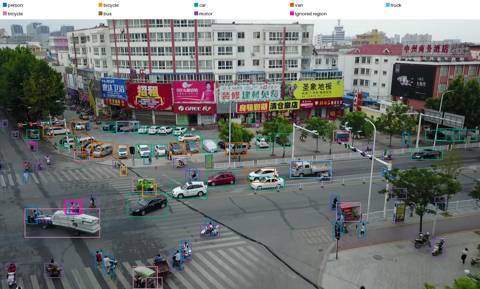

**Ground truth and ignored regions (magenta).** `train/uav0000138_00000_v/0000031`

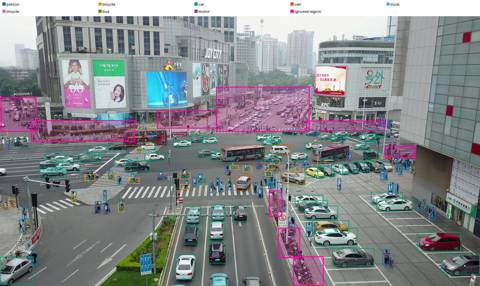

In [6]:
# Full-size overlays go to the ignored runs directory; the notebook shows small previews.
for key in (val_frames.sort("frame_id")["image_key"][-1], train_frames["image_key"][-1]):
    record = frames.row(by_predicate=pl.col("image_key") == key, named=True)
    overlay = draw_frame(
        SUBSET_ROOT / record["relative_path"],
        objects.filter(pl.col("image_key") == key),
        ignored.filter(pl.col("image_key") == key),
        max_width=1600,
        should_label=False,
    )
    overlay.save(OUTPUT_DIRECTORY / f"{key.replace('/', '_')}_ground_truth.png")
    preview = BytesIO()
    overlay.resize((480, round(480 * overlay.height / overlay.width))).save(
        preview, "JPEG", quality=70
    )
    display(Markdown(f"**Ground truth and ignored regions (magenta).** `{key}`"))
    display(DisplayImage(data=preview.getvalue()))

## 4. Pretrained model

We load the official torchvision COCO weights of Faster R-CNN ResNet-50 FPN V2 and keep
the backbone, FPN, RPN head, RoI pooling and box head. Only the final box predictor is new,
with nine outputs: background plus eight classes. The detection cap is 500 per image, the
number of detections the submission scores.

In [7]:
model = build_faster_rcnn(allow_download=TRAINING["allow_weight_download"], **SETTINGS["model"]).to(
    DEVICE
)
predictor = model.roi_heads.box_predictor
if not isinstance(predictor, FastRCNNPredictor):
    raise TypeError("Unexpected box predictor.")
pl.DataFrame(
    {
        "Weights": ["FasterRCNN_ResNet50_FPN_V2_Weights.COCO_V1"],
        "Classes with background": [predictor.cls_score.out_features],
        "Resize": [f"{SETTINGS['model']['min_size']}/{SETTINGS['model']['max_size']}"],
        "Anchor sizes": [str(SETTINGS["model"]["anchor_sizes"])],
        "Detections per image": [model.roi_heads.detections_per_img],
        "Ignore threshold": [model.rpn.ignore_threshold],
        "Trainable parameters": [sum(p.numel() for p in model.parameters() if p.requires_grad)],
    }
)

Weights,Classes with background,Resize,Anchor sizes,Detections per image,Ignore threshold,Trainable parameters
str,i64,str,str,i64,f64,i64
"""FasterRCNN_ResNet50_FPN_V2_Wei…",9,"""384/640""","""[32, 64, 128, 256, 512]""",500,0.5,43066684


## 5. Ignored regions as "don't care"

The data description asks to treat ignored regions as don't care during training. Stock
torchvision would sample anchors and proposals inside them as background. Our RPN and
RoI heads keep the stock matching, then mark every background sample whose area lies at
least half inside one ignored region as excluded, so the samplers never draw it. Positive
samples are never changed. We count the effect on the training frame with the most
ignored regions.

In [8]:
ignore_counts = ignored.filter(pl.col("split") == "train").group_by("image_key").len()
ignore_key = ignore_counts.sort(["len", "image_key"], descending=[True, False])["image_key"][0]
ignore_index = train_frames["image_key"].to_list().index(ignore_key)
image, target = train_dataset[ignore_index]
ignore_summary = summarize_ignore_assignment(
    model, image.to(DEVICE), {name: value.to(DEVICE) for name, value in target.items()}
)
if ignore_summary["anchor_positives_aware"] != ignore_summary["anchor_positives_stock"]:
    raise ValueError("Ignore handling changed positive anchors.")
if ignore_summary["proposal_positives_aware"] != ignore_summary["proposal_positives_stock"]:
    raise ValueError("Ignore handling changed positive proposals.")
with pl.Config(tbl_rows=20, fmt_str_lengths=60):
    display(
        pl.DataFrame(
            {
                "Count": ["frame", *ignore_summary],
                "Value": [ignore_key, *map(str, ignore_summary.values())],
            }
        )
    )

Count,Value
str,str
"""frame""","""train/uav0000138_00000_v/0000001"""
"""ignored_regions""","""9"""
"""anchors""","""61380"""
"""anchor_negatives_stock""","""55328"""
"""anchor_negatives_excluded""","""3237"""
"""anchor_positives_stock""","""3437"""
"""anchor_positives_aware""","""3437"""
"""proposals""","""1151"""
"""proposal_negatives_stock""","""871"""


## 6. Short overfit run

We train on the eight training frames in a fixed order, so every pass sees the same images.
The run passes when all losses are finite and the mean loss of the last pass is clearly
below the first pass. The optimizer and loop are the shared RetinaNet ones: SGD with
momentum, linear warmup and two step decays, with mixed precision only on CUDA.

In [9]:
train_loader = make_loader(
    train_dataset, TRAINING["batch_size"], TRAINING["num_workers"], DEVICE, seed=TRAINING["seed"]
)
steps_per_pass = math.ceil(len(train_dataset) / TRAINING["batch_size"])
total_steps = steps_per_pass * TRAINING["overfit_passes"]
optimizer, scheduler = make_optimizer(
    model, TRAINING["learning_rate"], total_steps, TRAINING["warmup_steps"]
)
training_started = time.perf_counter()
history = train_steps(model, train_loader, optimizer, scheduler, DEVICE, total_steps)
training_seconds = time.perf_counter() - training_started
loss_check = compare_loss_windows(history, steps_per_pass)
is_loss_decreasing = loss_check["ratio"] < EVALUATION["loss_decrease_ratio"]
pl.DataFrame(
    [
        {
            "Optimizer updates": sum(row["optimizer_updated"] for row in history),
            "Training seconds": round(training_seconds, 1),
            "Seconds per update": round(training_seconds / len(history), 2),
            "First pass loss": round(loss_check["first_window_loss"], 4),
            "Last pass loss": round(loss_check["last_window_loss"], 4),
            "Last / first": round(loss_check["ratio"], 3),
            "Passes": is_loss_decreasing,
        }
    ]
)

Optimizer updates,Training seconds,Seconds per update,First pass loss,Last pass loss,Last / first,Passes
i64,f64,f64,f64,f64,f64,bool
48,176.3,3.67,3.424,1.421,0.415,true


In [10]:
loss_names = ["loss", "loss_objectness", "loss_rpn_box_reg", "loss_classifier", "loss_box_reg"]
loss_history = (
    pl.from_dicts(history)
    .with_row_index("Attempt", offset=1)
    .unpivot(index="Attempt", on=loss_names, variable_name="Loss", value_name="Value")
)
figure = px.line(
    loss_history,
    x="Attempt",
    y="Value",
    color="Loss",
    title="Training loss on eight fixed frames",
    labels={"Attempt": "Training step", "Value": "Loss value"},
)
figure.show(renderer="plotly_mimetype")

## 7. Short evaluation on four validation frames

We predict in original-image pixels and evaluate against the original COCO records of the
selected frames, including the per-category crowd records that make detections inside
ignored regions free. We report COCO AP at the canonical cap of 100 detections, which the
RetinaNet results use, and at 500, the submission cap. The competition metric is not
defined in the assignment text, so these COCO numbers are an unverified stand-in.
AP_small uses the ground-truth area in original pixels.

In [11]:
val_dataset = IgnoreAwareDetectionDataset(SUBSET_ROOT, val_frames, objects, ignored)
val_loader = make_loader(val_dataset, EVALUATION["batch_size"], EVALUATION["num_workers"], DEVICE)
val_predictions, val_image_ids, val_speed = predict_loader(model, val_loader, DEVICE)
records = predictions_to_coco(val_predictions, val_image_ids)
(OUTPUT_DIRECTORY / "val_predictions.json").write_text(json.dumps(records) + "\n")
metrics = evaluate_detections(SUBSET_ROOT / "val/annotations_coco.json", records, val_image_ids)
pl.DataFrame(
    [
        {
            "maxDets": cap,
            "mAP": result["map"],
            "AP50": result["ap50"],
            "AP small": result["ap_small"],
            "Frames": result["image_count"],
        }
        for cap, result in (("100", metrics["max_dets_100"]), ("500", metrics["max_dets_500"]))
    ]
).with_columns(
    pl.lit(max(len(prediction["boxes"]) for prediction in val_predictions)).alias(
        "Max detections in a frame"
    ),
    pl.lit(round(val_speed["milliseconds_per_frame"], 1)).alias("Inference ms/frame"),
)

maxDets,mAP,AP50,AP small,Frames,Max detections in a frame,Inference ms/frame
str,f64,f64,f64,i64,i32,f64
"""100""",0.024342,0.079087,0.026291,4,350,1653.7
"""500""",0.024342,0.079087,0.026291,4,350,1653.7


## 8. Submission file for four test frames

We convert test predictions with the shared exporter: labels 1 to 8 become classes 0 to 7,
boxes become top-left `x y width height` in original pixels, and each frame keeps at most
500 detections. We reread the written CSV, validate it against the selected rows of
`test_images.csv`, and check that every box lies inside its image.

In [12]:
test_dataset = IgnoreAwareDetectionDataset(SUBSET_ROOT, test_frames, objects, ignored)
test_loader = make_loader(test_dataset, EVALUATION["batch_size"], EVALUATION["num_workers"], DEVICE)
test_predictions, test_image_ids, test_speed = predict_loader(model, test_loader, DEVICE)
if test_image_ids != [int(value) for value in test_frames["image_id"]]:
    raise ValueError("Test prediction order differs from the frame table.")
sample = pl.read_csv(
    SUBSET_ROOT / "test_images.csv", schema_overrides={"image_id": pl.String}
).select("image_id", pl.lit("").alias("PredictionString"))
submission_path = OUTPUT_DIRECTORY / "submission_smoke.csv"
build_submission(test_predictions, test_frames, sample).write_csv(submission_path)
written = pl.read_csv(
    submission_path, schema_overrides={"image_id": pl.String, "PredictionString": pl.String}
)
submission_check = validate_submission(written, sample)

sizes = {
    row["submission_id"]: (row["image_width"], row["image_height"])
    for row in test_frames.iter_rows(named=True)
}
outside = 0
for row in written.iter_rows(named=True):
    values = (row["PredictionString"] or "").split()
    image_width, image_height = sizes[row["image_id"]]
    for index in range(0, len(values), 6):
        x, y, box_width, box_height = map(float, values[index + 2 : index + 6])
        outside += x + box_width > image_width + 1e-3 or y + box_height > image_height + 1e-3
if outside:
    raise ValueError(f"{outside} submitted boxes exceed their image.")
display(
    pl.DataFrame(
        [{**submission_check, "Boxes outside image": outside, "File": submission_path.name}]
    )
)
written.with_columns(pl.col("PredictionString").str.slice(0, 80))

images,detections,empty_images,Boxes outside image,File
i64,i64,i64,i64,str
4,619,0,0,"""submission_smoke.csv"""


image_id,PredictionString
str,str
"""clip_004_0000001""","""2 0.61333525 910.71326 316.173…"
"""clip_004_0000011""","""2 0.48583281 611.19562 207.851…"
"""clip_004_0000021""","""2 0.65820974 909.341 304.34146…"
"""clip_004_0000031""","""2 0.49238485 935.6239 324.6275…"


## 9. Smoke-test summary

Every criterion below comes from this execution. Peak memory is the process maximum
resident set size; on CUDA we also report peak allocated GPU memory.

In [13]:
criteria = {
    "Losses finite": all(math.isfinite(row["loss"]) for row in history),
    "Loss decreases on fixed frames": is_loss_decreasing,
    "Ignore handling excludes negatives": ignore_summary["anchor_negatives_excluded"] > 0,
    "Positives unchanged by ignore handling": (
        ignore_summary["anchor_positives_aware"] == ignore_summary["anchor_positives_stock"]
        and ignore_summary["proposal_positives_aware"] == ignore_summary["proposal_positives_stock"]
    ),
    "Evaluation returns metrics": metrics["max_dets_500"]["map"] is not None,
    "Submission validates": submission_check["images"] == test_frames.height,
    "Train and validation flights disjoint": not train_flights & val_flights,
}
summary = {
    **criteria,
    "Inference ms/frame": round(val_speed["milliseconds_per_frame"], 1),
    "Peak RAM MiB": round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024),
    "Peak GPU MiB": (
        round(torch.cuda.max_memory_allocated() / 1024**2) if DEVICE.type == "cuda" else None
    ),
    "Notebook seconds": round(time.perf_counter() - NOTEBOOK_STARTED),
}
(OUTPUT_DIRECTORY / "smoke_summary.json").write_text(json.dumps(summary, indent=2) + "\n")
if not all(criteria.values()):
    raise AssertionError(
        f"Failed criteria: {[name for name, passed in criteria.items() if not passed]}"
    )
pl.DataFrame({"Check": list(summary), "Value": [str(value) for value in summary.values()]})

Check,Value
str,str
"""Losses finite""","""True"""
"""Loss decreases on fixed frames""","""True"""
"""Ignore handling excludes negat…","""True"""
"""Positives unchanged by ignore …","""True"""
"""Evaluation returns metrics""","""True"""
…,…
"""Train and validation flights d…","""True"""
"""Inference ms/frame""","""1653.7"""
"""Peak RAM MiB""","""2236"""


## 10. Limitations

The subset has eight training frames, so the loss decrease shows that gradients flow
through both stages, not that the model generalises. The four-frame metrics are not
results. CPU timing is a diagnostic; graded inference speed must be measured on the
experiment GPU. The competition metric is not defined in the assignment text.